# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country/countries **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country/countries and its story

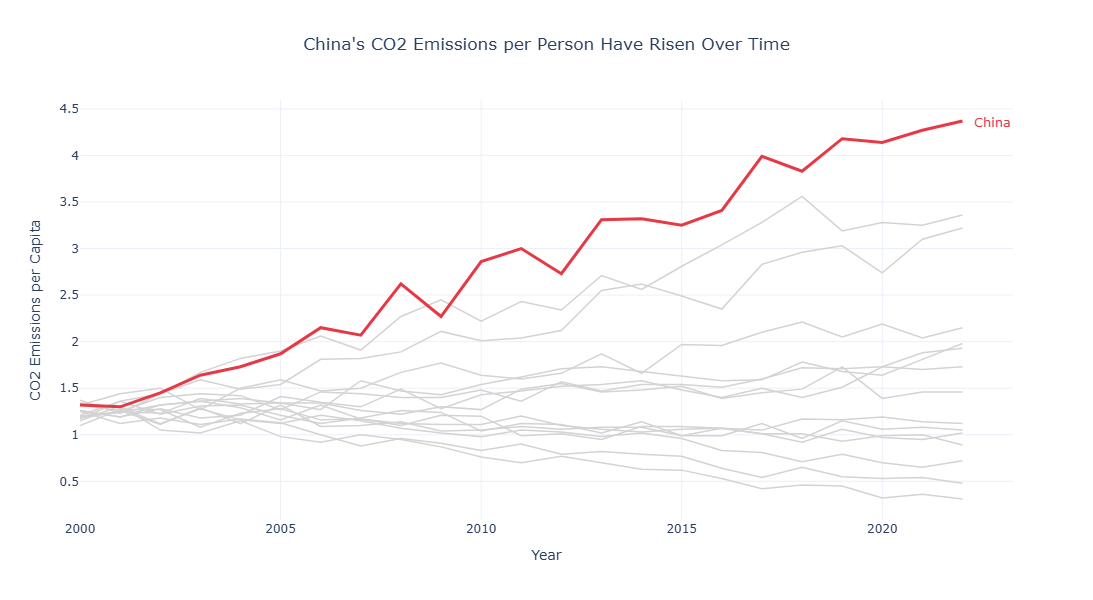

In [3]:

# Task 1: CO2 per capita for all countries

fig = go.Figure()

# Highlight China
highlight_country = 'China'

# Plot all countries in grey
for country in df['Country'].unique():
    country_data = df[df['Country'] == country].sort_values('Year')

    if country == highlight_country:
        continue

    fig.add_trace(go.Scatter(
        x=country_data['Year'],
        y=country_data['CO2_per_capita'],
        mode='lines',
        line=dict(color='#D3D3D3', width=1.5),
        name=country,
        showlegend=False,
        hovertemplate=country + '<br>Year: %{x}<br>CO2 per capita: %{y:.2f}<extra></extra>'
    ))

# Plot China in a highlighted colour
china_data = df[df['Country'] == highlight_country].sort_values('Year')

fig.add_trace(go.Scatter(
    x=china_data['Year'],
    y=china_data['CO2_per_capita'],
    mode='lines',
    line=dict(color='#E63946', width=3),
    name=highlight_country,
    showlegend=False
))

# Direct label at the end of China's line
last = china_data.iloc[-1]

fig.add_annotation(
    x=last['Year'],
    y=last['CO2_per_capita'],
    text='China',
    showarrow=False,
    xshift=30,
    font=dict(color='#E63946', size=13)
)

fig.update_layout(
    title="China's CO2 Emissions per Person Have Risen Over Time",
    title_x=0.5,
    template='plotly_white',
    xaxis_title='Year',
    yaxis_title='CO2 Emissions per Capita',
    height=600,
    showlegend=False
)

fig.show()


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

Asian countries: <StringArray>
['China', 'India', 'Japan', 'South Korea', 'Indonesia']
Length: 5, dtype: str


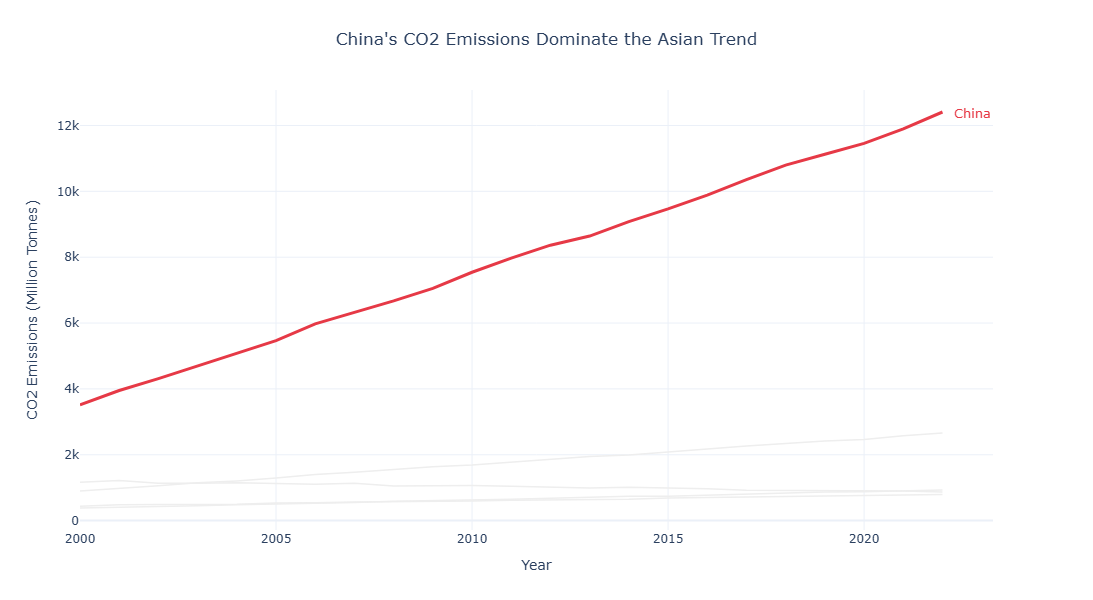

In [4]:

# Task 2: CO2 emissions over time for all Asian countries

# Step 1: Select all Asian countries
asia_df = df[df['Region'] == 'Asia'].copy()

# Check available Asian countries
print("Asian countries:", asia_df['Country'].unique())

# Step 2: Choose China as the highlighted country
highlight_country = 'China'

fig = go.Figure()

# Step 3: Plot all other Asian countries in grey
for country in asia_df['Country'].unique():
    country_data = asia_df[
        asia_df['Country'] == country
    ].sort_values('Year')

    if country == highlight_country:
        continue

    fig.add_trace(go.Scatter(
        x=country_data['Year'],
        y=country_data['CO2_Mt'],
        mode='lines',
        line=dict(color='#EEEEEE', width=1.5),
        showlegend=False,
        hovertemplate=country + '<br>Year: %{x}<br>CO2: %{y:.1f} Mt<extra></extra>'
    ))

# Step 4: Highlight China
china_data = asia_df[
    asia_df['Country'] == highlight_country
].sort_values('Year')

fig.add_trace(go.Scatter(
    x=china_data['Year'],
    y=china_data['CO2_Mt'],
    mode='lines',
    line=dict(color='#E63946', width=3),
    showlegend=False
))

# Step 5: Add direct label
last = china_data.iloc[-1]

fig.add_annotation(
    x=last['Year'],
    y=last['CO2_Mt'],
    text='China',
    showarrow=False,
    xshift=30,
    font=dict(color='#E63946', size=13)
)

# Step 6: Chart design
fig.update_layout(
    title="China's CO2 Emissions Dominate the Asian Trend",
    title_x=0.5,
    template='plotly_white',
    xaxis_title='Year',
    yaxis_title='CO2 Emissions (Million Tonnes)',
    height=600,
    showlegend=False,
    margin=dict(l=80, r=100, t=90, b=70)
)

fig.show()
